In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("/content/earthquake_1995-2023.csv")
df.head()

,title,magnitude,date_time,cdi,mmi,alert,tsunami,sig,net,nst,dmin,gap,magType,depth,latitude,longitude,location,continent,country
0,"M 6.5 - 42 km W of Sola, Vanuatu",6.5,16/08/2023 12:47,7,4,green,0,657,us,114,7.177000,25.0,mww,192.955,-13.8814,167.1580,"Sola, Vanuatu",NaN,Vanuatu
1,"M 6.5 - 43 km S of Intipucá, El Salvador",6.5,19/07/2023 00:22,8,6,yellow,0,775,us,92,0.679000,40.0,mww,69.727,12.8140,-88.1265,"Intipucá, El Salvador",NaN,NaN
2,"M 6.6 - 25 km ESE of Loncopué, Argentina",6.6,17/07/2023 03:05,7,5,green,0,899,us,70,1.634000,28.0,mww,171.371,-38.1911,-70.3731,"Loncopué, Argentina",South America,Argentina
3,"M 7.2 - 98 km S of Sand Point, Alaska",7.2,16/07/2023 06:48,6,6,green,1,860,us,173,0.907000,36.0,mww,32.571,54.3844,-160.6990,"Sand Point, Alaska",NaN,NaN
4,M 7.3 - Alaska Peninsula,7.3,16/07/2023 06:48,0,5,NaN,1,820,at,79,0.879451,172.8,Mi,21.000,54.4900,-160.7960,Alaska Peninsula,NaN,NaN


In [ ]:
import matplotlib as mlt

In [ ]:
df.columns

Index(['title', 'magnitude', 'date_time', 'cdi', 'mmi', 'alert', 'tsunami',
       'sig', 'net', 'nst', 'dmin', 'gap', 'magType', 'depth', 'latitude',
       'longitude', 'location', 'continent', 'country'],
      dtype='object')

1.Horizontal Bar Chart (Alert Levels)
This plot represents the total count of earthquakes categorized by their alert level. It allows for immediate visual ranking to easily identify which alert levels are the most and least frequent in the dataset.

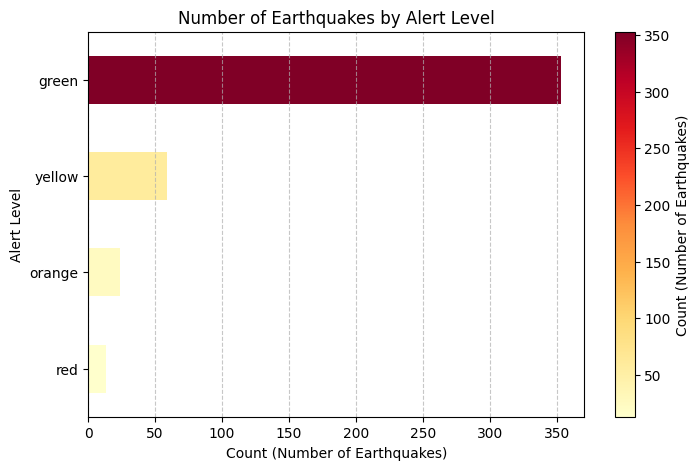

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import numpy as np

plt.figure(figsize=(8, 5))
alert_counts = df['alert'].value_counts().sort_values(ascending=True)

# 1. Define a colormap and normalize the data based on min/max counts
cmap = plt.get_cmap('YlOrRd')  # Yellow-Orange-Red highlights higher numbers
norm = mcolors.Normalize(vmin=alert_counts.min(), vmax=alert_counts.max())

# 2. Generate a list of colors for each bar based on its value
bar_colors = cmap(norm(alert_counts.values))

# 3. Plot the horizontal bar chart passing the generated colors
ax = alert_counts.plot(kind='barh', color=bar_colors)

# 4. Create and attach the colorbar to the plot
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([]) # Required for the colorbar to render correctly
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Count (Number of Earthquakes)')

plt.title('Number of Earthquakes by Alert Level')
plt.xlabel('Count (Number of Earthquakes)')
plt.ylabel('Alert Level')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

2. Histograms (Magnitude & Depth)
These plots represent the underlying shape and distribution of the data. The magnitude histograms show which earthquake sizes happen most frequently, while the logarithmic depth histogram reveals the frequency of shallow versus deep events by stretching out heavily skewed data.

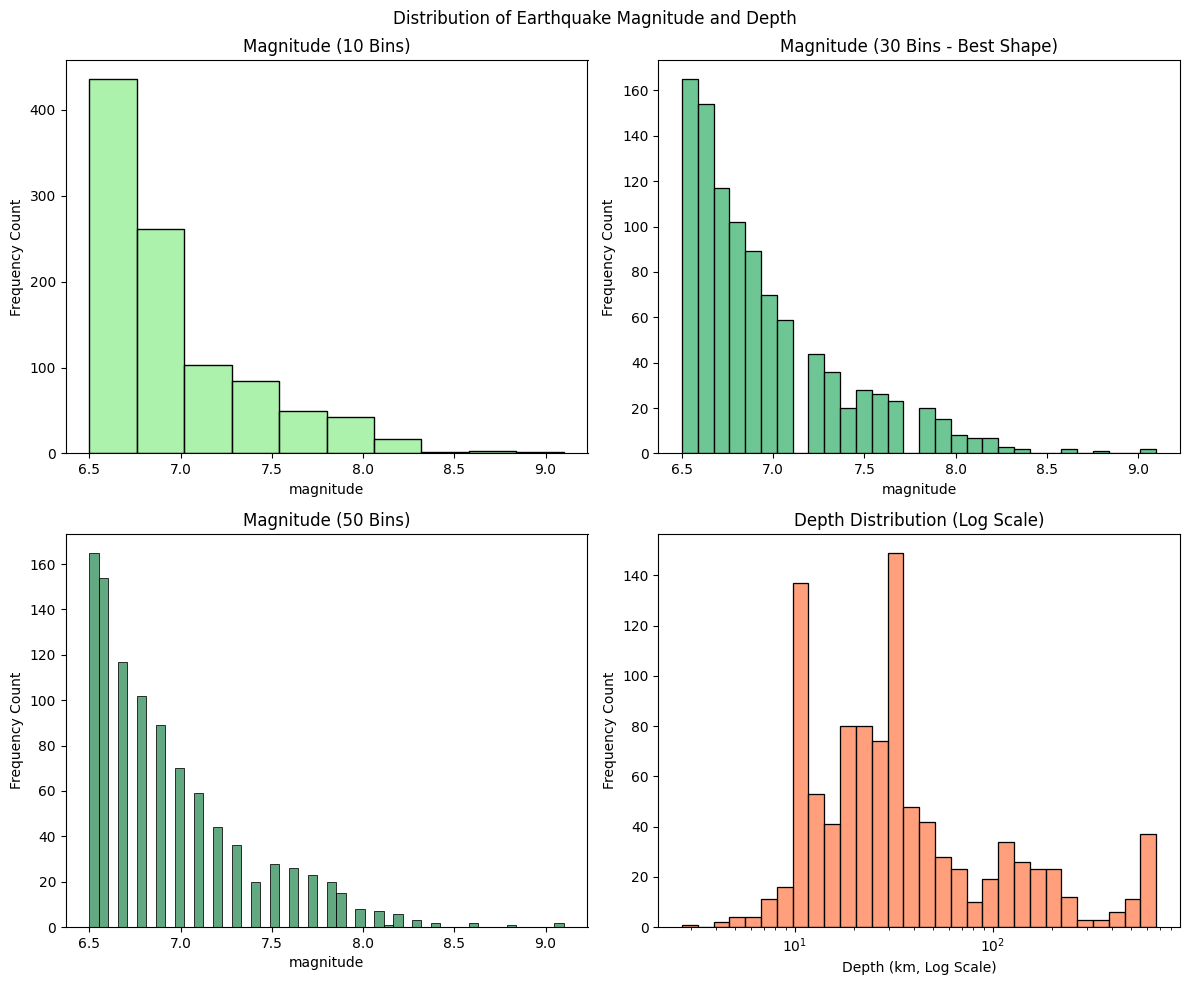

In [ ]:
# 2. Histogram with varying bins and log scale
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Distribution of Earthquake Magnitude and Depth')

# Bins comparison
sns.histplot(df['magnitude'], bins=10, ax=axes[0, 0], color='lightgreen').set(title='Magnitude (10 Bins)')
sns.histplot(df['magnitude'], bins=30, ax=axes[0, 1], color='mediumseagreen').set(title='Magnitude (30 Bins - Best Shape)')
sns.histplot(df['magnitude'], bins=50, ax=axes[1, 0], color='seagreen').set(title='Magnitude (50 Bins)')

# Log scale for skewed depth data
sns.histplot(df['depth'], bins=30, log_scale=True, ax=axes[1, 1], color='coral')
axes[1, 1].set_title('Depth Distribution (Log Scale)')
axes[1, 1].set_xlabel('Depth (km, Log Scale)')

for ax in axes.flat:
    ax.set_ylabel('Frequency Count')
plt.tight_layout()
plt.show()

3. Box Plot (Depth by Magnitude)
This plot summarizes the spread of earthquake depths across different magnitude categories. It highlights the median depth, the middle 50% range (the box), and extreme deep or shallow outliers (the isolated dots) for each severity level.

/tmp/ipykernel_4008/317504334.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='mag_band', y='depth', data=df, palette='Set2')


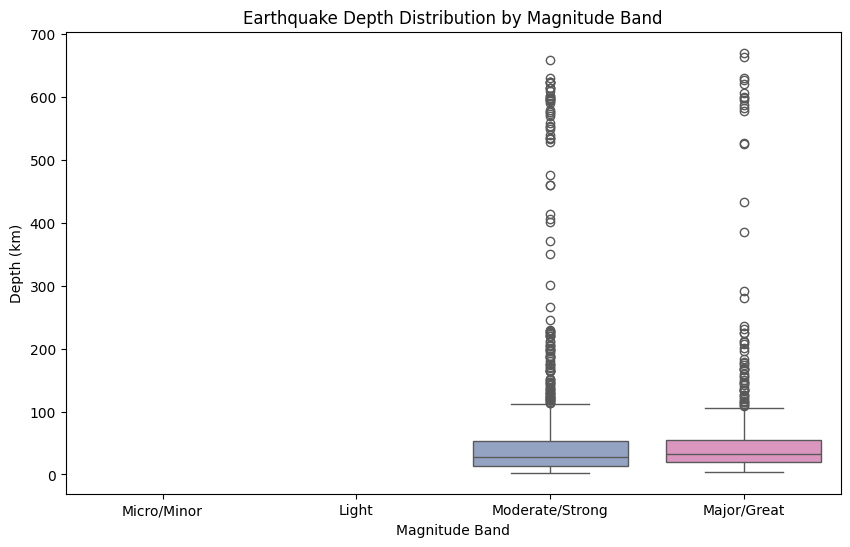

In [ ]:
# Create magnitude bands for grouping
df['mag_band'] = pd.cut(df['magnitude'], bins=[0, 3, 5, 7, 10], labels=['Micro/Minor', 'Light', 'Moderate/Strong', 'Major/Great'])

# 3. Box Plot
plt.figure(figsize=(10, 6))
sns.boxplot(x='mag_band', y='depth', data=df, palette='Set2')
plt.title('Earthquake Depth Distribution by Magnitude Band')
plt.xlabel('Magnitude Band')
plt.ylabel('Depth (km)')
plt.show()

In [ ]:
df.head()

,title,magnitude,date_time,cdi,mmi,alert,tsunami,sig,net,nst,dmin,gap,magType,depth,latitude,longitude,location,continent,country,mag_band
0,"M 6.5 - 42 km W of Sola, Vanuatu",6.5,16/08/2023 12:47,7,4,green,0,657,us,114,7.177000,25.0,mww,192.955,-13.8814,167.1580,"Sola, Vanuatu",NaN,Vanuatu,Moderate/Strong
1,"M 6.5 - 43 km S of Intipucá, El Salvador",6.5,19/07/2023 00:22,8,6,yellow,0,775,us,92,0.679000,40.0,mww,69.727,12.8140,-88.1265,"Intipucá, El Salvador",NaN,NaN,Moderate/Strong
2,"M 6.6 - 25 km ESE of Loncopué, Argentina",6.6,17/07/2023 03:05,7,5,green,0,899,us,70,1.634000,28.0,mww,171.371,-38.1911,-70.3731,"Loncopué, Argentina",South America,Argentina,Moderate/Strong
3,"M 7.2 - 98 km S of Sand Point, Alaska",7.2,16/07/2023 06:48,6,6,green,1,860,us,173,0.907000,36.0,mww,32.571,54.3844,-160.6990,"Sand Point, Alaska",NaN,NaN,Major/Great
4,M 7.3 - Alaska Peninsula,7.3,16/07/2023 06:48,0,5,NaN,1,820,at,79,0.879451,172.8,Mi,21.000,54.4900,-160.7960,Alaska Peninsula,NaN,NaN,Major/Great


4. Violin Plot (Depth Density)
Similar to the box plot, this visualizes depths across magnitude bands, but it additionally represents the full probability density. Thicker, wider sections of the "violin" represent the specific depths where earthquakes are most heavily concentrated.

/tmp/ipykernel_4008/2609289388.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='mag_band', y='depth', data=df, palette='Set2', inner='quartile')


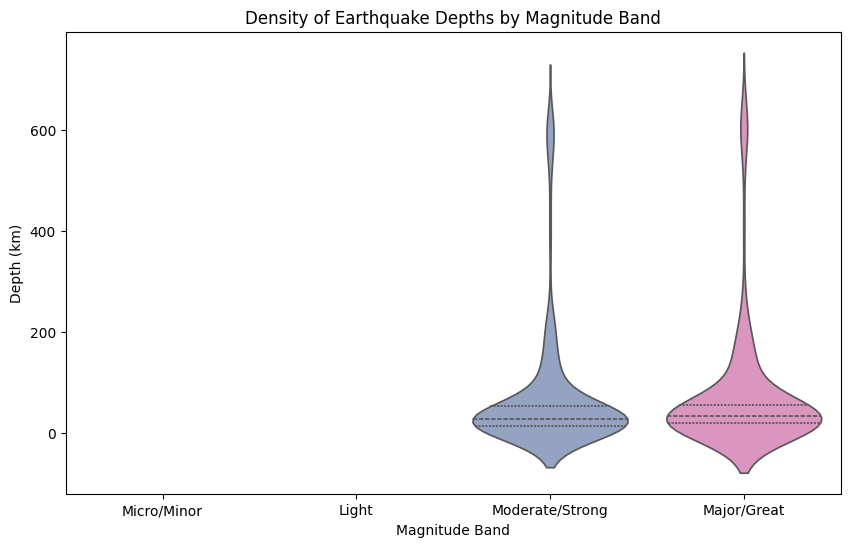

In [ ]:
# 4. Violin Plot
plt.figure(figsize=(10, 6))
sns.violinplot(x='mag_band', y='depth', data=df, palette='Set2', inner='quartile')
plt.title('Density of Earthquake Depths by Magnitude Band')
plt.xlabel('Magnitude Band')
plt.ylabel('Depth (km)')
plt.show()

5. Donut Chart (Alert Proportions)
This chart represents the part-to-whole relationship of earthquake alerts. It clearly displays the exact percentage share of each alert category relative to the total number of recorded alerts.

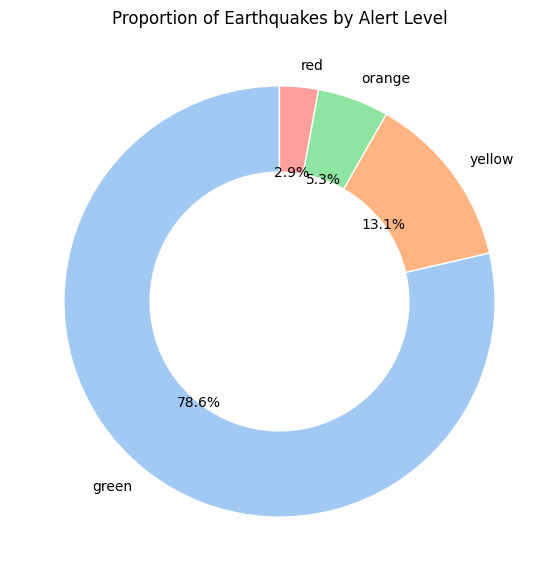

In [ ]:
# 5. Donut Chart
plt.figure(figsize=(7, 7))
alert_counts = df['alert'].dropna().value_counts()
plt.pie(alert_counts, labels=alert_counts.index, autopct='%1.1f%%',
        startangle=90, colors=sns.color_palette('pastel'),
        wedgeprops=dict(width=0.4, edgecolor='w'))
plt.title('Proportion of Earthquakes by Alert Level')
plt.show()

In [ ]:
df.head()

,title,magnitude,date_time,cdi,mmi,alert,tsunami,sig,net,nst,...,gap,magType,depth,latitude,longitude,location,continent,country,mag_band,year
0,"M 6.5 - 42 km W of Sola, Vanuatu",6.5,2023-08-16 12:47:00,7,4,green,0,657,us,114,...,25.0,mww,192.955,-13.8814,167.1580,"Sola, Vanuatu",NaN,Vanuatu,Moderate/Strong,2023
1,"M 6.5 - 43 km S of Intipucá, El Salvador",6.5,2023-07-19 00:22:00,8,6,yellow,0,775,us,92,...,40.0,mww,69.727,12.8140,-88.1265,"Intipucá, El Salvador",NaN,NaN,Moderate/Strong,2023
2,"M 6.6 - 25 km ESE of Loncopué, Argentina",6.6,2023-07-17 03:05:00,7,5,green,0,899,us,70,...,28.0,mww,171.371,-38.1911,-70.3731,"Loncopué, Argentina",South America,Argentina,Moderate/Strong,2023
3,"M 7.2 - 98 km S of Sand Point, Alaska",7.2,2023-07-16 06:48:00,6,6,green,1,860,us,173,...,36.0,mww,32.571,54.3844,-160.6990,"Sand Point, Alaska",NaN,NaN,Major/Great,2023
4,M 7.3 - Alaska Peninsula,7.3,2023-07-16 06:48:00,0,5,NaN,1,820,at,79,...,172.8,Mi,21.000,54.4900,-160.7960,Alaska Peninsula,NaN,NaN,Major/Great,2023


8. Heatmap (Correlation Matrix)
This grid represents the mathematical relationships between all numeric variables in the dataset. Red squares indicate variables that increase together (positive correlation), blue squares indicate variables that move in opposite directions (negative correlation), and white indicates no connection.

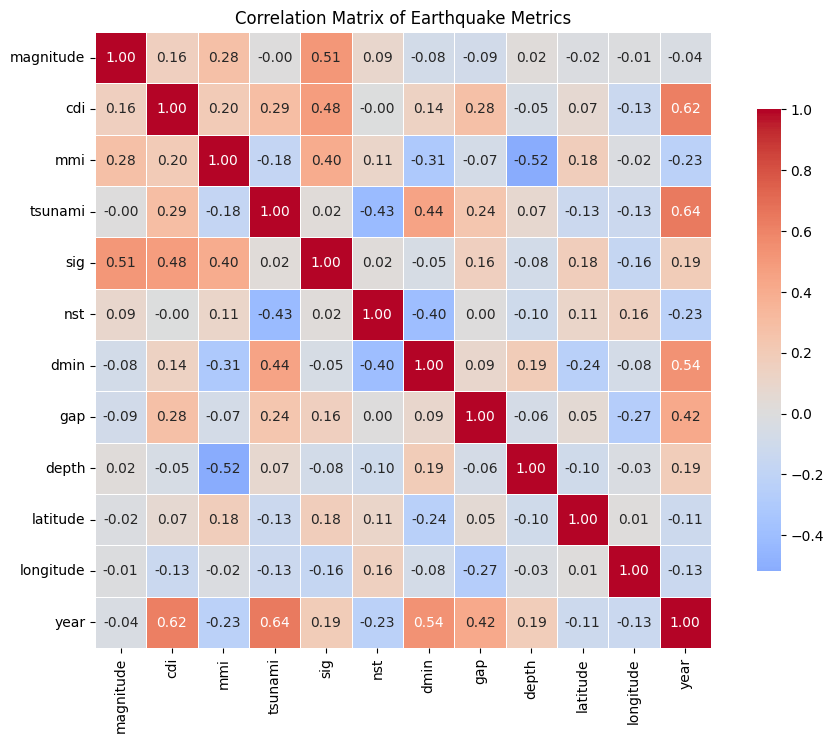

In [ ]:
# 8. Heatmap of numeric columns
plt.figure(figsize=(12, 8))
# Select only numeric columns for correlation
numeric_cols = df.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

# Diverging colormap centered at zero
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .75})
plt.title('Correlation Matrix of Earthquake Metrics')
plt.show()

Pie Chart (Alert Proportions)
This chart represents the part-to-whole relationship of earthquake alert levels. It clearly displays the exact percentage share of each individual alert category relative to the total number of recorded alerts, allowing you to instantly see which alerts make up the majority of the dataset.

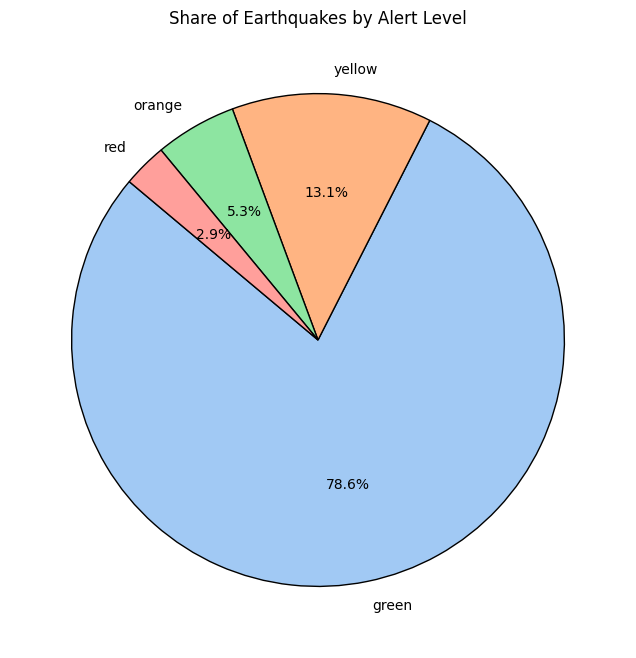

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Drop missing values in 'alert' to ensure a clean chart
alert_counts = df['alert'].dropna().value_counts()

# Create the Pie Chart
plt.figure(figsize=(8, 8))
plt.pie(alert_counts,
        labels=alert_counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=sns.color_palette('pastel'),
        wedgeprops={'edgecolor': 'black', 'linewidth': 1})

plt.title('Share of Earthquakes by Alert Level')
plt.show()

6. Scatter Plot (Magnitude vs. Significance)
This plot maps every individual earthquake to represent the linear relationship between its physical magnitude and its calculated significance score. It reveals whether these two metrics increase together and highlights if high-significance events consistently trigger tsunamis.

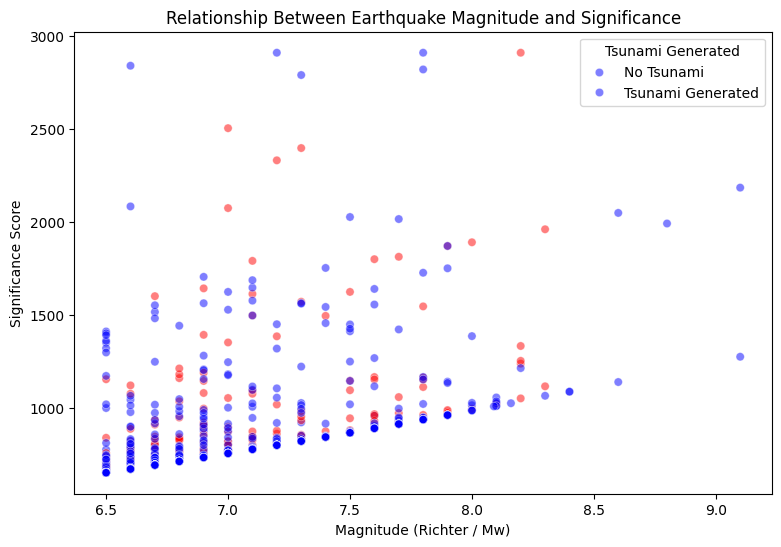

In [ ]:
# 6. Scatter Plot with transparency and color categorization
plt.figure(figsize=(9, 6))
sns.scatterplot(x='magnitude', y='sig', hue='tsunami', alpha=0.5,
                palette={0: 'blue', 1: 'red'}, data=df)
plt.title('Relationship Between Earthquake Magnitude and Significance')
plt.xlabel('Magnitude (Richter / Mw)')
plt.ylabel('Significance Score')
plt.legend(title='Tsunami Generated', labels=['No Tsunami', 'Tsunami Generated'])
plt.show()

Line Chart (Annual Trend)
This plot represents the total volume of recorded earthquakes chronologically over time. It illustrates historical trends year by year, making it easy to identify general increases, decreases, or sudden spikes in earthquake activity.

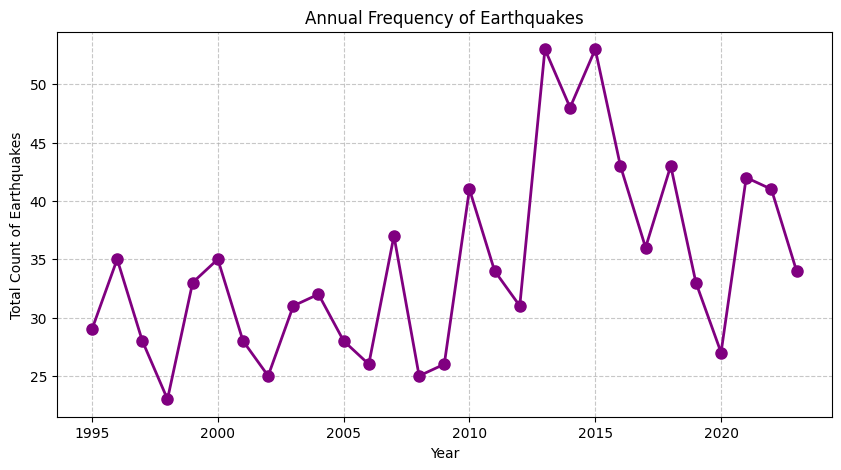

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Convert the 'date_time' string column to proper datetime objects
df['date_time'] = pd.to_datetime(df['date_time'], errors='coerce')

# 2. Extract the year to group the data
df['year'] = df['date_time'].dt.year

# 3. Count the total number of earthquakes per year
yearly_counts = df.groupby('year').size()

# 4. Create the Line Chart
plt.figure(figsize=(10, 5))
yearly_counts.plot(kind='line', marker='o', color='purple', linewidth=2, markersize=8)

plt.title('Annual Frequency of Earthquakes')
plt.xlabel('Year')
plt.ylabel('Total Count of Earthquakes')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()